In [1]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
calendar = pd.read_csv("../data/raw/calendar.csv")

calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [4]:
calendar.shape

(1969, 14)

In [5]:
calendar.columns

Index(['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd',
       'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2',
       'snap_CA', 'snap_TX', 'snap_WI'],
      dtype='object')

In [6]:
calendar.dtypes

date            object
wm_yr_wk         int64
weekday         object
wday             int64
month            int64
year             int64
d               object
event_name_1    object
event_type_1    object
event_name_2    object
event_type_2    object
snap_CA          int64
snap_TX          int64
snap_WI          int64
dtype: object

In [7]:
calendar.isnull().sum()

date               0
wm_yr_wk           0
weekday            0
wday               0
month              0
year               0
d                  0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64

In [8]:
calendar["date"] = pd.to_datetime(calendar["date"])

In [9]:
calendar.dtypes

date            datetime64[ns]
wm_yr_wk                 int64
weekday                 object
wday                     int64
month                    int64
year                     int64
d                       object
event_name_1            object
event_type_1            object
event_name_2            object
event_type_2            object
snap_CA                  int64
snap_TX                  int64
snap_WI                  int64
dtype: object

In [10]:
sales = pd.read_csv("../data/raw/sales_train_validation.csv")


In [11]:
sales.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


In [12]:
sales.shape

(30490, 1919)

In [13]:
sales.columns[:15]

Index(['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1',
       'd_2', 'd_3', 'd_4', 'd_5', 'd_6', 'd_7', 'd_8', 'd_9'],
      dtype='object')

In [14]:
print("Shape:", sales.shape)

print("Number of SKUs:", sales["item_id"].nunique())

print("Number of stores:", sales["store_id"].nunique())

print("Number of categories:", sales["cat_id"].nunique())

print("Number of departments:", sales["dept_id"].nunique())

print("Total missing values:", sales.isnull().sum().sum())

sales[["d_1", "d_2", "d_3", "d_4", "d_5"]].describe()

Shape: (30490, 1919)
Number of SKUs: 3049
Number of stores: 10
Number of categories: 3
Number of departments: 7
Total missing values: 0


,d_1,d_2,d_3,d_4,d_5
count,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000
mean,1.070220,1.041292,0.780026,0.833454,0.627944
std,5.126689,5.365468,3.667454,4.415141,3.379344
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000
max,360.000000,436.000000,207.000000,323.000000,296.000000


In [15]:
small_sales = sales[
    [
        "item_id",
        "store_id",
        "d_1",
        "d_2",
        "d_3",
        "d_4",
        "d_5"
    ]
].head(3)

small_sales

,item_id,store_id,d_1,d_2,d_3,d_4,d_5
0,HOBBIES_1_001,CA_1,0,0,0,0,0
1,HOBBIES_1_002,CA_1,0,0,0,0,0
2,HOBBIES_1_003,CA_1,0,0,0,0,0


In [16]:
small_long = small_sales.melt(
    id_vars=["item_id", "store_id"],
    var_name="day",
    value_name="sales"
)

small_long

,item_id,store_id,day,sales
0,HOBBIES_1_001,CA_1,d_1,0
1,HOBBIES_1_002,CA_1,d_1,0
2,HOBBIES_1_003,CA_1,d_1,0
3,HOBBIES_1_001,CA_1,d_2,0
4,HOBBIES_1_002,CA_1,d_2,0
5,HOBBIES_1_003,CA_1,d_2,0
6,HOBBIES_1_001,CA_1,d_3,0
7,HOBBIES_1_002,CA_1,d_3,0
8,HOBBIES_1_003,CA_1,d_3,0
9,HOBBIES_1_001,CA_1,d_4,0


In [17]:
small_long = small_long.merge(
    calendar[["d", "date", "weekday", "month", "year"]],
    left_on="day",
    right_on="d",
    how="left"
)

small_long.head(10)

,item_id,store_id,day,sales,d,date,weekday,month,year
0,HOBBIES_1_001,CA_1,d_1,0,d_1,2011-01-29,Saturday,1,2011
1,HOBBIES_1_002,CA_1,d_1,0,d_1,2011-01-29,Saturday,1,2011
2,HOBBIES_1_003,CA_1,d_1,0,d_1,2011-01-29,Saturday,1,2011
3,HOBBIES_1_001,CA_1,d_2,0,d_2,2011-01-30,Sunday,1,2011
4,HOBBIES_1_002,CA_1,d_2,0,d_2,2011-01-30,Sunday,1,2011
5,HOBBIES_1_003,CA_1,d_2,0,d_2,2011-01-30,Sunday,1,2011
6,HOBBIES_1_001,CA_1,d_3,0,d_3,2011-01-31,Monday,1,2011
7,HOBBIES_1_002,CA_1,d_3,0,d_3,2011-01-31,Monday,1,2011
8,HOBBIES_1_003,CA_1,d_3,0,d_3,2011-01-31,Monday,1,2011
9,HOBBIES_1_001,CA_1,d_4,0,d_4,2011-02-01,Tuesday,2,2011


In [18]:
sales["item_id"].value_counts().head(10)

item_id
HOBBIES_1_001    10
HOBBIES_1_002    10
HOBBIES_1_003    10
HOBBIES_1_004    10
HOBBIES_1_005    10
HOBBIES_1_006    10
HOBBIES_1_007    10
HOBBIES_1_008    10
HOBBIES_1_009    10
HOBBIES_1_010    10
Name: count, dtype: int64

In [19]:
sku_sales = (
    sales
    .drop(columns=["id", "dept_id", "cat_id", "state_id"])
    .set_index(["item_id", "store_id"])
    .sum(axis=1)
    .sort_values(ascending=False)
)

sku_sales.head(10)

item_id      store_id
FOODS_3_090  CA_3        250502
FOODS_3_586  TX_2        192835
             TX_3        150122
             CA_3        134386
FOODS_3_090  CA_1        127203
             WI_3        121434
             TX_2        119496
             TX_3        114854
FOODS_3_252  TX_2        114153
FOODS_3_586  TX_1        112454
dtype: int64

In [20]:
target = sales[
    (sales["item_id"] == "FOODS_3_090") &
    (sales["store_id"] == "CA_3")
]

target

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
8412,FOODS_3_090_CA_3_validation,FOODS_3_090,FOODS_3,FOODS,CA_3,CA,108,132,102,120,...,129,160,204,86,100,88,77,141,139,130


In [21]:
day_columns = [col for col in sales.columns if col.startswith("d_")]

target_daily = target[day_columns].T

target_daily.columns = ["sales"]

target_daily.head()

,sales
d_1,108
d_2,132
d_3,102
d_4,120
d_5,106


In [22]:
target_daily = target_daily.reset_index()

target_daily.columns = ["day", "sales"]

target_daily.head()

,day,sales
0,d_1,108
1,d_2,132
2,d_3,102
3,d_4,120
4,d_5,106


In [23]:
target_daily = target_daily.merge(
    calendar[["d", "date", "weekday", "month", "year"]],
    left_on="day",
    right_on="d",
    how="left"
)

target_daily.head()

,day,sales,d,date,weekday,month,year
0,d_1,108,d_1,2011-01-29,Saturday,1,2011
1,d_2,132,d_2,2011-01-30,Sunday,1,2011
2,d_3,102,d_3,2011-01-31,Monday,1,2011
3,d_4,120,d_4,2011-02-01,Tuesday,2,2011
4,d_5,106,d_5,2011-02-02,Wednesday,2,2011


In [24]:
target_daily = target_daily.sort_values("date")

In [25]:
target_daily.head()

,day,sales,d,date,weekday,month,year
0,d_1,108,d_1,2011-01-29,Saturday,1,2011
1,d_2,132,d_2,2011-01-30,Sunday,1,2011
2,d_3,102,d_3,2011-01-31,Monday,1,2011
3,d_4,120,d_4,2011-02-01,Tuesday,2,2011
4,d_5,106,d_5,2011-02-02,Wednesday,2,2011


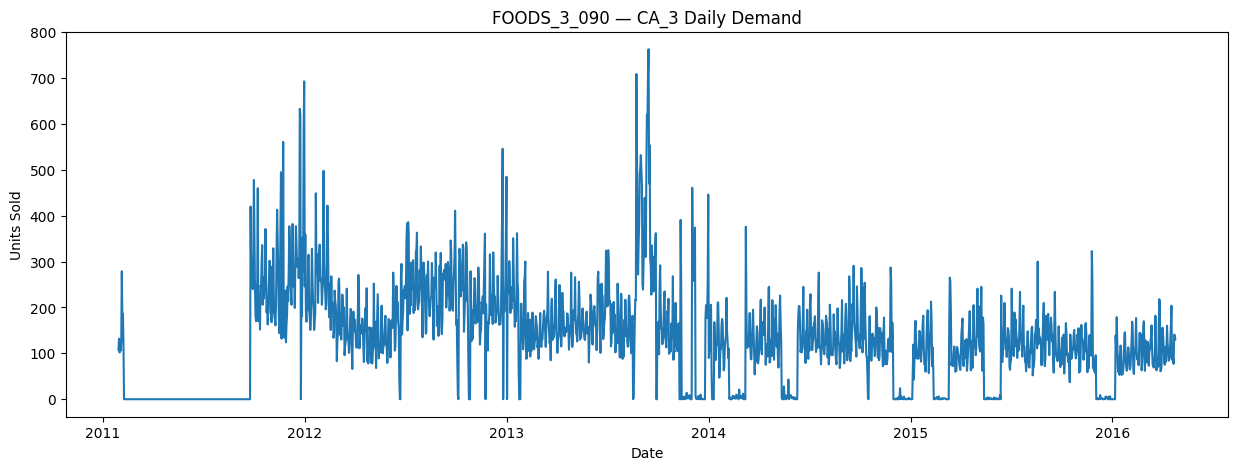

In [26]:
plt.figure(figsize=(15, 5))

plt.plot(
    target_daily["date"],
    target_daily["sales"]
)

plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.title("FOODS_3_090 — CA_3 Daily Demand")

plt.show()

In [27]:
target_daily["rolling_7"] = (
    target_daily["sales"]
    .rolling(window=7)
    .mean()
)

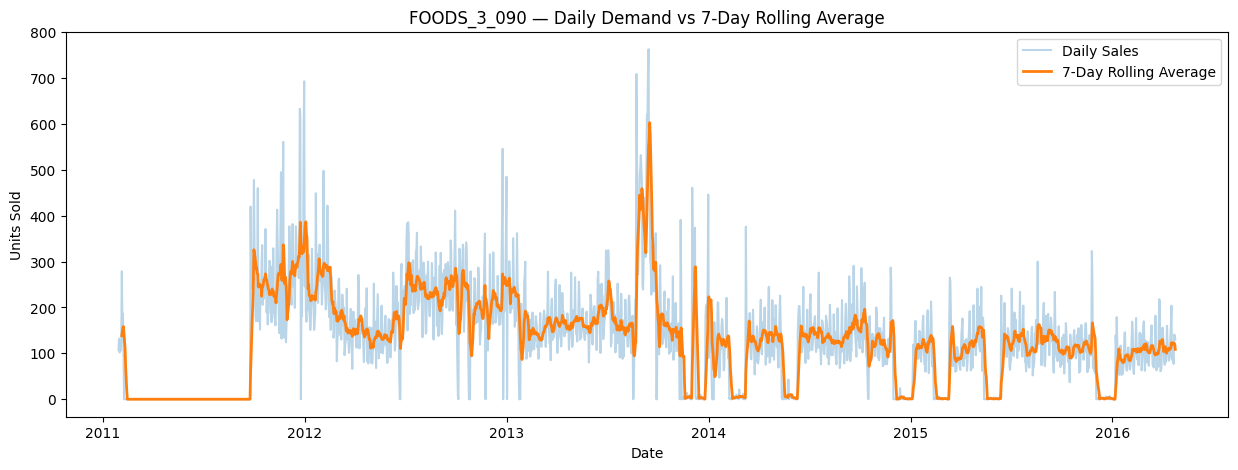

In [28]:
plt.figure(figsize=(15, 5))

plt.plot(
    target_daily["date"],
    target_daily["sales"],
    alpha=0.3,
    label="Daily Sales"
)

plt.plot(
    target_daily["date"],
    target_daily["rolling_7"],
    linewidth=2,
    label="7-Day Rolling Average"
)

plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.title("FOODS_3_090 — Daily Demand vs 7-Day Rolling Average")
plt.legend()

plt.show()

In [29]:
target_daily["sales"].describe()

count    1913.000000
mean      130.947203
std       108.611717
min         0.000000
25%        28.000000
50%       126.000000
75%       189.000000
max       763.000000
Name: sales, dtype: float64

In [30]:
target_daily["sales"].mean()

np.float64(130.94720334553057)

In [31]:
target_daily["sales"].median()

np.float64(126.0)

In [32]:
target_daily["sales"].std()

np.float64(108.61171693810788)

In [33]:
(target_daily["sales"] == 0).mean()

np.float64(0.1876633559853633)

In [34]:
print(
    "Zero-sales percentage:",
    (target_daily["sales"] == 0).mean() * 100
)

Zero-sales percentage: 18.76633559853633


In [35]:
weekday_demand = (
    target_daily
    .groupby("weekday")["sales"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

weekday_demand

weekday
Monday       118.219780
Tuesday      105.241758
Wednesday    107.490842
Thursday     117.087912
Friday       149.333333
Saturday     175.091241
Sunday       143.956204
Name: sales, dtype: float64

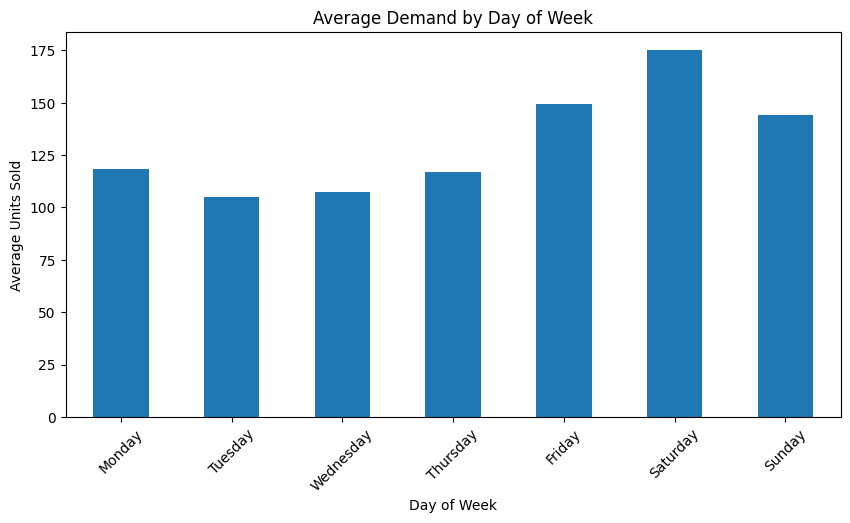

In [36]:
plt.figure(figsize=(10, 5))

weekday_demand.plot(kind="bar")

plt.xlabel("Day of Week")
plt.ylabel("Average Units Sold")
plt.title("Average Demand by Day of Week")

plt.xticks(rotation=45)

plt.show()

In [37]:
overall_mean = target_daily["sales"].mean()

weekday_summary = pd.DataFrame({
    "avg_sales": weekday_demand,
    "difference_from_mean": weekday_demand - overall_mean,
    "percentage_vs_mean": (weekday_demand / overall_mean - 1) * 100
})

weekday_summary

,avg_sales,difference_from_mean,percentage_vs_mean
weekday,,,
Monday,118.219780,-12.727423,-9.719507
Tuesday,105.241758,-25.705445,-19.630389
Wednesday,107.490842,-23.456361,-17.912838
Thursday,117.087912,-13.859291,-10.583877
Friday,149.333333,18.386130,14.040873
Saturday,175.091241,44.144038,33.711325
Sunday,143.956204,13.009001,9.934539


In [38]:
overall_mean = target_daily["sales"].mean()

weekday_demand = (
    target_daily
    .groupby("weekday")["sales"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

weekday_index = weekday_demand / overall_mean

weekday_index

weekday
Monday       0.902805
Tuesday      0.803696
Wednesday    0.820872
Thursday     0.894161
Friday       1.140409
Saturday     1.337113
Sunday       1.099345
Name: sales, dtype: float64

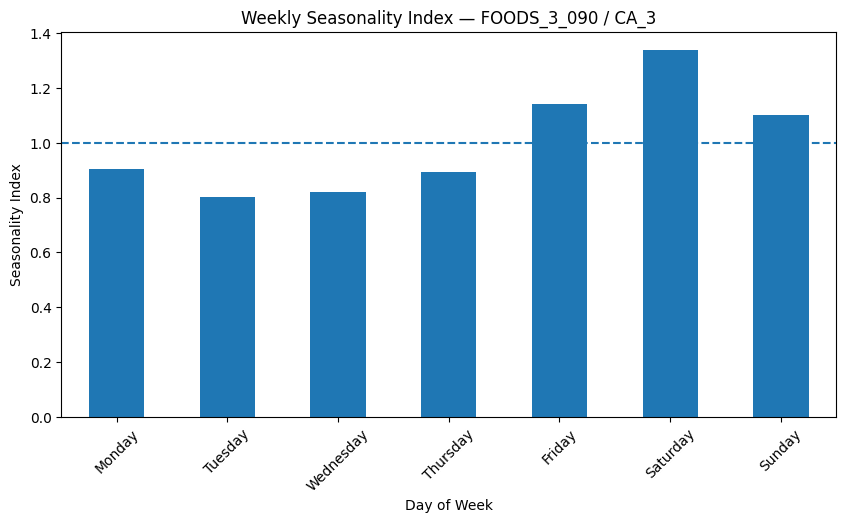

In [39]:
plt.figure(figsize=(10, 5))

weekday_index.plot(kind="bar")

plt.axhline(
    1,
    linestyle="--"
)

plt.xlabel("Day of Week")
plt.ylabel("Seasonality Index")
plt.title("Weekly Seasonality Index — FOODS_3_090 / CA_3")

plt.xticks(rotation=45)

plt.show()

In [40]:
monthly_demand = (
    target_daily
    .groupby("month")["sales"]
    .mean()
)

monthly_demand

month
1     143.765823
2     103.588235
3     101.790323
4     112.344828
5      85.064516
6     105.820000
7     141.019355
8     143.470968
9     191.420000
10    169.070968
11    150.446667
12    135.845161
Name: sales, dtype: float64

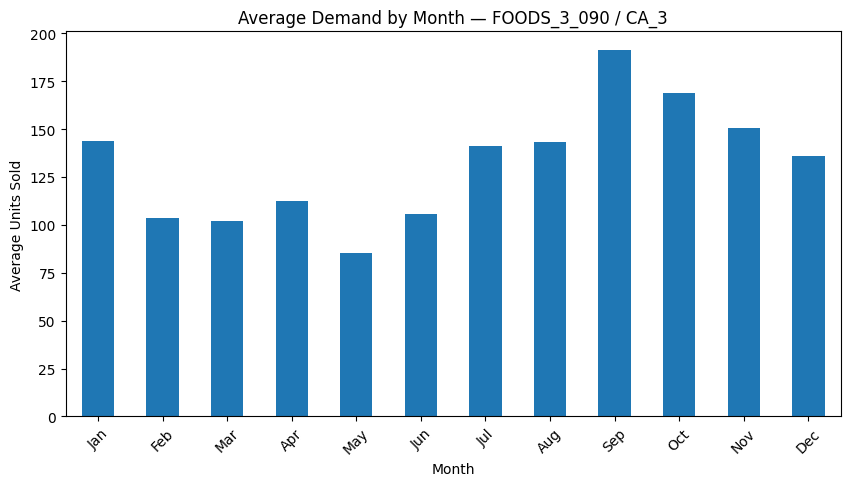

In [41]:
plt.figure(figsize=(10, 5))

monthly_demand.plot(kind="bar")

plt.xlabel("Month")
plt.ylabel("Average Units Sold")
plt.title("Average Demand by Month — FOODS_3_090 / CA_3")

plt.xticks(
    range(12),
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ],
    rotation=45
)

plt.show()

In [42]:
ts = target_daily[["date", "sales"]].copy()

ts = ts.set_index("date")

ts.head()

,sales
date,
2011-01-29,108
2011-01-30,132
2011-01-31,102
2011-02-01,120
2011-02-02,106


In [43]:
ts = ts.asfreq("D")

In [44]:
ts.index.min(), ts.index.max(), len(ts)

(Timestamp('2011-01-29 00:00:00'), Timestamp('2016-04-24 00:00:00'), 1913)

In [45]:
ts = target_daily[["date", "sales"]].copy()

ts = ts.set_index("date")

ts.head()

,sales
date,
2011-01-29,108
2011-01-30,132
2011-01-31,102
2011-02-01,120
2011-02-02,106


In [46]:
ts = ts.asfreq("D")

print("Start:", ts.index.min())
print("End:", ts.index.max())
print("Observations:", len(ts))

Start: 2011-01-29 00:00:00
End: 2016-04-24 00:00:00
Observations: 1913


In [47]:
print("Missing sales:", ts["sales"].isna().sum())

Missing sales: 0


In [48]:
decomposition = seasonal_decompose(
    ts["sales"],
    model="additive",
    period=7
)

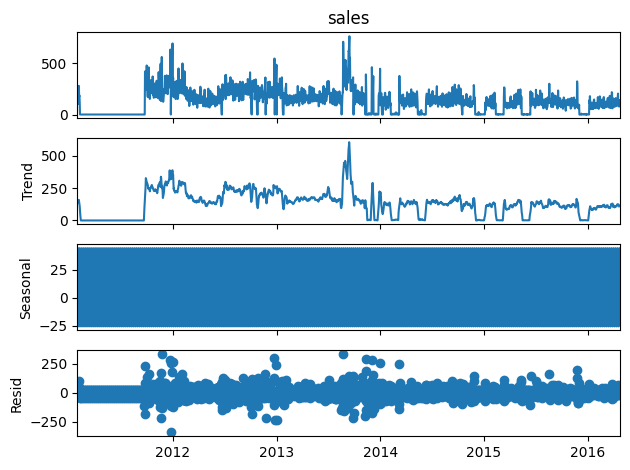

In [49]:
decomposition.plot()

plt.show()

In [50]:
print("Start:", ts.index.min())
print("End:", ts.index.max())
print("Total observations:", len(ts))

Start: 2011-01-29 00:00:00
End: 2016-04-24 00:00:00
Total observations: 1913


In [51]:
test_size = 28

train = ts.iloc[:-test_size].copy()
test = ts.iloc[-test_size:].copy()

In [52]:
print("Train start:", train.index.min())
print("Train end:", train.index.max())

print()

print("Test start:", test.index.min())
print("Test end:", test.index.max())

print()

print("Train observations:", len(train))
print("Test observations:", len(test))

Train start: 2011-01-29 00:00:00
Train end: 2016-03-27 00:00:00

Test start: 2016-03-28 00:00:00
Test end: 2016-04-24 00:00:00

Train observations: 1885
Test observations: 28


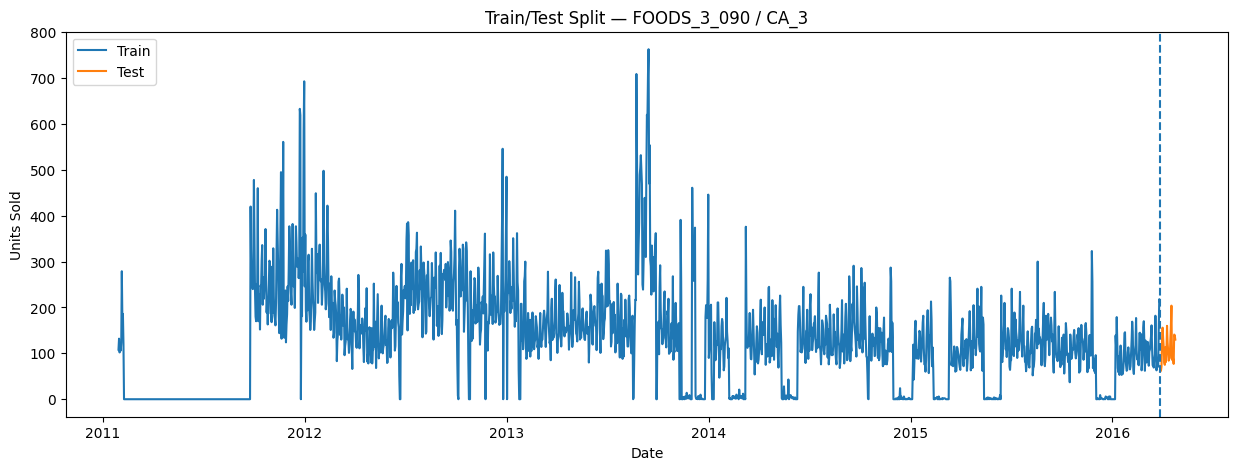

In [53]:
plt.figure(figsize=(15, 5))

plt.plot(
    train.index,
    train["sales"],
    label="Train"
)

plt.plot(
    test.index,
    test["sales"],
    label="Test"
)

plt.axvline(
    test.index[0],
    linestyle="--"
)

plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.title("Train/Test Split — FOODS_3_090 / CA_3")

plt.legend()

plt.show()

In [54]:
last_train_value = train["sales"].iloc[-1]

naive_forecast = pd.Series(
    last_train_value,
    index=test.index
)

naive_forecast.head()

date
2016-03-28    212
2016-03-29    212
2016-03-30    212
2016-03-31    212
2016-04-01    212
Freq: D, dtype: int64

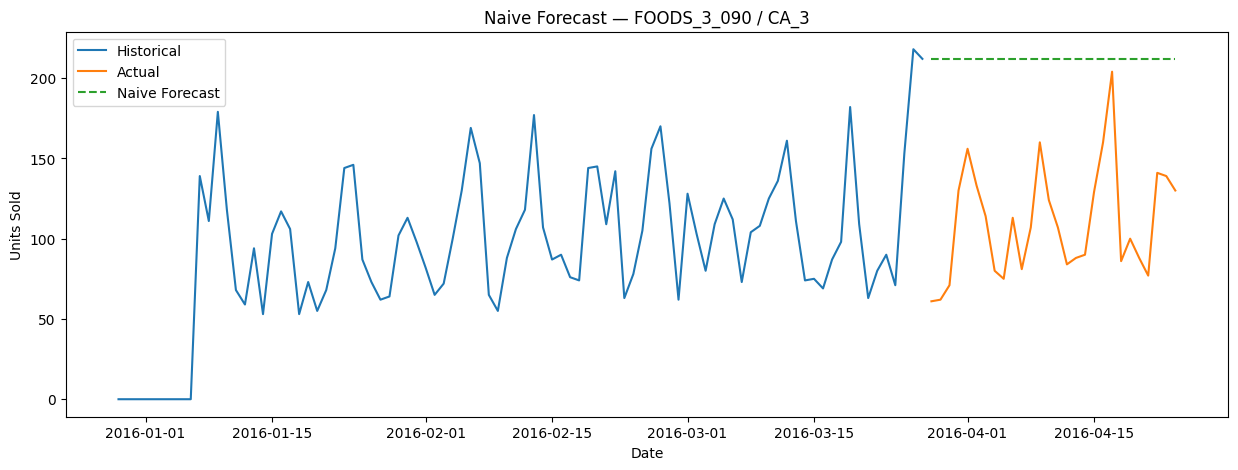

In [55]:
plt.figure(figsize=(15, 5))

plt.plot(
    train.index[-90:],
    train["sales"].iloc[-90:],
    label="Historical"
)

plt.plot(
    test.index,
    test["sales"],
    label="Actual"
)

plt.plot(
    naive_forecast.index,
    naive_forecast,
    label="Naive Forecast",
    linestyle="--"
)

plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.title("Naive Forecast — FOODS_3_090 / CA_3")

plt.legend()
plt.show()

In [56]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    test["sales"],
    naive_forecast
)

print("MAE:", mae)

MAE: 101.64285714285714


In [57]:
rmse = np.sqrt(
    mean_squared_error(
        test["sales"],
        naive_forecast
    )
)

print("RMSE:", rmse)

RMSE: 107.23072587383045


In [58]:
wape = (
    np.abs(test["sales"] - naive_forecast).sum()
    / test["sales"].sum()
) * 100

print("WAPE:", wape, "%")

WAPE: 92.10355987055017 %


In [59]:
print("Naive Forecast Performance")
print("---------------------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("WAPE:", round(wape, 2), "%")

Naive Forecast Performance
---------------------------
MAE : 101.64
RMSE: 107.23
WAPE: 92.1 %


In [60]:
# Seasonal Naive Forecast (weekly seasonality)
seasonal_period = 7

seasonal_naive_forecast = train["sales"].iloc[-seasonal_period:].to_numpy()

# Repeat the last 7 days to cover the test period
seasonal_naive_forecast = np.tile(
    seasonal_naive_forecast,
    int(np.ceil(len(test) / seasonal_period))
)[:len(test)]

print("Forecast length:", len(seasonal_naive_forecast))
print("Test length:", len(test))

Forecast length: 28
Test length: 28


In [61]:
seasonal_mae = mean_absolute_error(
    test["sales"],
    seasonal_naive_forecast
)

seasonal_rmse = np.sqrt(
    mean_squared_error(
        test["sales"],
        seasonal_naive_forecast
    )
)

seasonal_wape = (
    np.abs(test["sales"].to_numpy() - seasonal_naive_forecast).sum()
    / test["sales"].sum()
) * 100

print("Seasonal Naive Forecast Performance")
print("------------------------------------")
print("MAE :", round(seasonal_mae, 2))
print("RMSE:", round(seasonal_rmse, 2))
print("WAPE:", round(seasonal_wape, 2), "%")

Seasonal Naive Forecast Performance
------------------------------------
MAE : 32.64
RMSE: 44.55
WAPE: 29.58 %


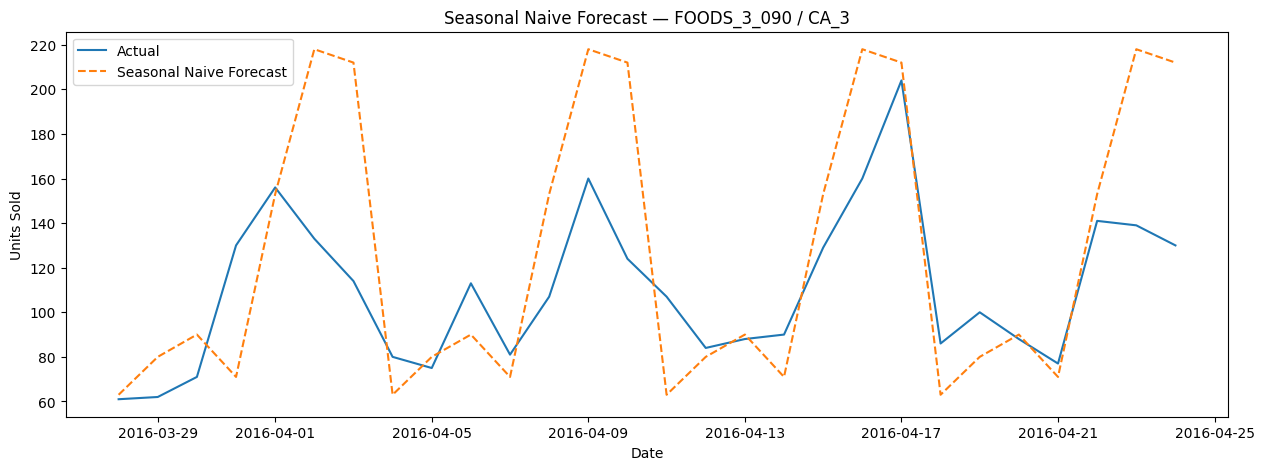

In [62]:
plt.figure(figsize=(15, 5))

plt.plot(
    test.index,
    test["sales"],
    label="Actual",
)

plt.plot(
    test.index,
    seasonal_naive_forecast,
    label="Seasonal Naive Forecast",
    linestyle="--",
)

plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.title("Seasonal Naive Forecast — FOODS_3_090 / CA_3")
plt.legend()
plt.show()

In [63]:
seasonal_mae = mean_absolute_error(
    test["sales"],
    seasonal_naive_forecast
)

print("Seasonal Naive MAE:", round(seasonal_mae, 2))

Seasonal Naive MAE: 32.64


In [64]:
seasonal_rmse = np.sqrt(
    mean_squared_error(
        test["sales"],
        seasonal_naive_forecast
    )
)

print("Seasonal Naive RMSE:", round(seasonal_rmse, 2))

Seasonal Naive RMSE: 44.55


In [65]:
seasonal_wape = (
    np.abs(
        test["sales"].to_numpy()
        - seasonal_naive_forecast
    ).sum()
    / test["sales"].sum()
) * 100

print("Seasonal Naive WAPE:", round(seasonal_wape, 2), "%")

Seasonal Naive WAPE: 29.58 %


In [66]:
seasonal_wape = (
    np.abs(
        test["sales"].to_numpy()
        - seasonal_naive_forecast
    ).sum()
    / test["sales"].sum()
) * 100

print("Seasonal Naive WAPE:", round(seasonal_wape, 2), "%")

Seasonal Naive WAPE: 29.58 %


In [67]:
comparison = pd.DataFrame({
    "Model": ["Naive", "Seasonal Naive"],
    "MAE": [mae, seasonal_mae],
    "RMSE": [rmse, seasonal_rmse],
    "WAPE (%)": [wape, seasonal_wape]
})

comparison

,Model,MAE,RMSE,WAPE (%)
0,Naive,101.642857,107.230726,92.103560
1,Seasonal Naive,32.642857,44.550934,29.579288
